# HW 3: Intro to PyTorch and Neural Nets with MNIST

In this assignment, you'll explore PyTorch fundamentals by implementing a basic **Multi-Layer Perceptron (MLP)** to classify handwritten digits from the **MNIST** dataset.

You will learn:
- How to manipulate tensors
- How to load and batch data with DataLoaders
- How to define and train neural networks in PyTorch
- How to evaluate model performance and visualize results



## Part 1: Exploring Pytorch and building a MLP (15 pts)
In the first part of this homework we'll walk through how to build a basic MLP in pytorch so that you can attempt the other parts with the knowledge you've gained.

## What Are Tensors?

Tensors are the fundamental data structure in PyTorch — they’re like NumPy arrays but with GPU support.

A tensor is:
- A container for numerical data (integers, floats, etc.)
- Able to represent scalars (0D), vectors (1D), matrices (2D), and higher-dimensional arrays (3D+)
- The building block of all neural network operations

In this section, you’ll play around with tensor creation, reshaping, and conversion between NumPy arrays and PyTorch tensors.


In [1]:
import torch
import numpy as np

# Create a tensor from a list
## Basic 1D array of values.
a = torch.tensor([1.0, 2.0, 3.0])
print("Tensor a:", a)

# Create random tensors
## Generates a 2x3 tensor (matrix) or random values.

x = torch.randn(2, 3)
print("Shape of x:", x.shape)
print("x contents:\n", x)

# Reshape (view)
## Flattened a N-dimen array to 1D.
x_flat = x.view(-1)
print("Flattened x:", x_flat)

# Convert numpy to tensor
arr = np.array([[1, 2], [3, 4]])
tensor_from_np = torch.from_numpy(arr)
print("Tensor from numpy:\n", tensor_from_np)


Tensor a: tensor([1., 2., 3.])
Shape of x: torch.Size([2, 3])
x contents:
 tensor([[-0.1995, -0.9000,  0.6514],
        [-0.6876,  0.3782, -0.1025]])
Flattened x: tensor([-0.1995, -0.9000,  0.6514, -0.6876,  0.3782, -0.1025])
Tensor from numpy:
 tensor([[1, 2],
        [3, 4]])


## Using the Full MNIST Dataset

So far, you've only interacted with a portion of the MNIST dataset. Now we’ll work with the full dataset.
You’ll use PyTorch's built-in tools to:
- Download and cache the full MNIST dataset
- Apply transformations (normalization)
- Wrap it in a `DataLoader` for batching

This makes it easy to train models without worrying about manual preprocessing or batch management.


In [2]:
from torchvision.datasets import MNIST
from torch.utils.data import Dataset, DataLoader
# === Load raw MNIST ===
train_raw = MNIST(root="./data", train=True, download=True)
test_raw = MNIST(root="./data", train=False, download=True)

In [3]:
#We do need to normalize our data and convert it from a PIL image to a tensor

In [4]:
## Is a tuple containing image as the first item, and the label as the second item.
train_raw[0]

(<PIL.Image.Image image mode=L size=28x28>, 5)

In [5]:
def normalize(pil_img):
    """Convert PIL image to normalized PyTorch tensor."""
    img = np.array(pil_img, dtype=np.float32) / 255.0     # scale to [0, 1]
    img = (img - 0.1307) / 0.3081                          # normalize
    tensor = torch.tensor(img).unsqueeze(0)               # shape [1, 28, 28], 1 => Grayscale
    return tensor

In [6]:
image_tensor = normalize(train_raw[0][0])
image_tensor.shape

torch.Size([1, 28, 28])

In [ ]:
import matplotlib.pyplot as plt

# Convert to numpy for plotting
image_np = image_tensor.squeeze(0).numpy()  # shape: [28, 28]

# Plot using imshow
plt.imshow(image_np, cmap='gray')
plt.title("Manually Normalized Image (Label: {})".format(train_raw[0][1]))

plt.show()


## Understanding `Dataset` and `DataLoader`

In PyTorch, the `Dataset` and `DataLoader` classes are used to organize and efficiently load data for training and evaluation.

### `Dataset`
A `Dataset` object:
- Stores and manages the input data
- Implements two required methods:
  - `__len__()` – returns the number of examples
  - `__getitem__(idx)` – returns a single example (e.g., image and label)

By creating a custom `Dataset`, you have full control over how the data is loaded and preprocessed.

### `DataLoader`
A `DataLoader` takes a `Dataset` and:
- Batches multiple samples together
- Shuffles the data (optional)
- Handles parallel data loading for efficiency

Typical usage:

train_dataset = Dataset(data,other parameters)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)


In [8]:
## Creates the class MNIST_Dataset by us passing in the Dataset which was loaded in before.
## self references the object, raw_data references the data that we pass in.
## We are able to work with two functions in this, the length of the dataset and getting an item from the data set.

class MNIST_Dataset(Dataset):
    def __init__(self, raw_data):
        self.data = raw_data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, label = self.data[idx]
        image_tensor = normalize(image)
        return image_tensor, label


In [9]:
## Creates our MNIST_Dataset objects from our training and testing data.
train_data = MNIST_Dataset(train_raw)
test_data = MNIST_Dataset(test_raw)

## Creates two DataLoaders that improves efficiency when training.
train_loader = DataLoader(train_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)


In [ ]:
# Iterate through a dataloader

## We get an iterator by passing in our DataLoader train_loader into enumerate and set it equal to examples. The DataLoader returns batches of (data, label).
## Then, we call next which gives us a tuple of (index, item), our index is batch_idx the index of the batch, and our item is another tuple containing (example_data, example_labels),
## which is the data associated with that specific batch.

examples = enumerate(train_loader)
batch_idx, (example_data, example_labels) = next(examples)

fig = plt.figure()
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray')
    plt.title(f"Label: {example_labels[i].item()}")
    plt.xticks([])
    plt.yticks([])

In [11]:
#Building our Multi-layer perceptron

In [12]:
import torch.nn as nn
import torch.nn.functional as F

# Define a Multi-Layer Perceptron for MNIST classification
class MLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=32, hidden_dim2=11, dropout=0.5):
        super(MLP, self).__init__()
        #Your architecture comes here
        
        # First fully connected layer: input → hidden
        #fc1= fully connected layer 1

        ## Essentially, we assign the function nn.Linear to self.fc1, and when we call self.fc1, we pass in the parameter
        ## necessary for nn.Linear (where x is our input tensor) to run.
        ## This creates a layer that computes y = xW^T + b.
        ## It takes an vector of size input_dim, which is 784, and outputs a vector of size hidden_dim, which is 32.

        self.fc1 = nn.Linear(input_dim, hidden_dim)

        #dropout is a regularization technique used to prevent overfitting and can be created like

        ## This zeros out some of the values in our layer in order to prevent overfitting as said.
        ## Zeroing out some of the values essentially makes our MLP less reliant on certain neurons.
        self.dropout = nn.Dropout(dropout)

        # Second fully connected layer: hidden → hidden
        # These can be the same value, different values, its up to you to find a good architecture
        # You can also try just one hidden, or maybe more than 2, the design is up to you.
        self.fc2 = nn.Linear(hidden_dim, hidden_dim2)
        #We just need to be concerned about making sure the dimensions match
        
        # Final output layer: hidden → 10 output classes (corresponds to digits)
        self.out = nn.Linear(hidden_dim2, 10)

    def forward(self, x):
        #This is where the forward pass occurs with our data
        # B is for Batch

        # Flatten the input image: [B, 1, 28, 28] → [B, 784]
        x = x.flatten(start_dim=1)
        
        # Pass through first layer + ReLU + Dropout
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        
        # Pass through second layer + ReLU + Dropout
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        
        # Final output layer (no softmax; CrossEntropyLoss handles it)
        return self.out(x)


In [13]:
def train_one_epoch(model, dataloader, optimizer, criterion):

    ## model.train() essentially tells our nn.Module object that we are now training
    ## and effects some functions or modules in the object.
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    ## Each iteration of the DataLoader gives us a batch which has
    ## a total of 64 items.
    ##
    ## B is the Batch, which is 64 in this case.
    ## images is of size [B, 1, 28, 28].
    ##  B --> Batch-size or 64.
    ##  1 --> Grayscale
    ##  28 --> Height
    ##  28 --> Width.
    ## labels is of size [B].

    for images, labels in dataloader:
        ## Device is just whether we use the CPU or GPU and it moves the data in the DataLoader there.
        images, labels = images.to(device), labels.to(device)

        ## We then clear the optimizer by calling the zero gradient function. Optimizer is our
        ## object that holds the current state and will update the parameters based on the computed gradients.

        ## Then, we predict output for each sample in the batch with our model. (or our forward pass)

        ## We compute loss, then use backpropoagation to compute the gradients of loss w.r.t all model parameters.
        ## This allows the model to learn and more closely adjust weights to minimize loss.

        ## Finally, we take a "step" in the direction of the gradient and apply the computed gradients to update model weights.
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        ## This first calculates the total loss so that we can then caclulate the average loss per batch.
        ## This also calculates accuracy through the total number of correct labels, and the total number of labels.

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(dataloader), correct / total


In [14]:
def evaluate(model, dataloader, criterion):

    ## model.eval() sets the model in evaluation mode, same deal as model.train().
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    ## We disable the gradient computations that would normally be done during training, as we are only
    ## evaluating the models performance.

    ## Generally the same things, but we only do forward passes and return the average loss per batch and accuracy.

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    accuracy= correct / total
    return total_loss / len(dataloader), accuracy


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MLP().to(device)
# For now leave the loss function and optimizer + learning rate as they are.

## Cross Entropy Loss combines two functions we've heard of before LogSoftmax and negative LogLikelihoodLoss.
## It has its bonuses to using it over the two seperate functions together.

## Optimizer is our updater, essentially will update our parameters based on current state and computed gradients.

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# We'll track loss and accuracy for each epoch
train_losses = []
val_accuracies = []

# Split training set into train/val by ratio of 50k Train and 10k Val
train_subset, val_subset = torch.utils.data.random_split(train_data, [50000, 10000])
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=64)

for epoch in range(10):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, val_loader, criterion)
    
    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val Accuracy: {val_acc:.4f}")


Epoch 1 | Train Loss: 1.5726 | Val Accuracy: 0.8650
Epoch 2 | Train Loss: 1.2355 | Val Accuracy: 0.8729
Epoch 3 | Train Loss: 1.1670 | Val Accuracy: 0.8871
Epoch 4 | Train Loss: 1.1497 | Val Accuracy: 0.8861
Epoch 5 | Train Loss: 1.1123 | Val Accuracy: 0.8890
Epoch 6 | Train Loss: 1.0961 | Val Accuracy: 0.8848
Epoch 7 | Train Loss: 1.0883 | Val Accuracy: 0.8899
Epoch 8 | Train Loss: 1.0751 | Val Accuracy: 0.8890
Epoch 9 | Train Loss: 1.0713 | Val Accuracy: 0.8957
Epoch 10 | Train Loss: 1.0656 | Val Accuracy: 0.8954


In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()


In [17]:
test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f"Final Test Accuracy: {test_acc:.4f}")


Final Test Accuracy: 0.9051


## Reflection

Answer the following questions in this markdown cell:

1. What part of the training process was most confusing at first?
The most confusing part of the training process here was learning what the individual functions part of the PyTorch library were doing. I had sort of an idea of what they
would be doing but I like to be 100% sure they are doing the things I expect them to do. Cross Entropy Loss was also confusing, I don't believe we've talked about it officially
or maybe I misesd it in the slides, but figuring out what it did was hard looking at documentation.

2. Why do you suppose we use ReLU and dropout in the MLP, what happens if we don't use them?
ReLU, the activation function, is used in order to introduce nonlinearity back into the network. This allows the networks to become more complex and helps
in training and stacking multiple layers in deep networks. If we didn't use ReLU, the network would just be a sequence of linear operations, which is then
just a linear model, which is not what we want when training an MLP.

Dropout is used to prevent overfitting, we don't want the MLP to rely of a few neurons when its training and having the model be too complex. If we
dont use dropout, the model wil overfit, and lead to lower accuracy scores.

3. What would happen if we forgot to flatten the image?

We get an error that tells us the two matricies cannot be multiplied when running as they don't have the same shape.

4. What modifications, if any, can you make to this architecture to get a testing accuracy higher than 98% and in how many epochs?

We could add more layers to the MLP to reach a testing accuracy higher than 98%. We can also tune parameters such as the learning rate and dropout.
It would take roughly the same amount of epochs or a little more to reach 98%, more training can also help to get the testing accuracy higher.

5. What is the highest accuracy you can get in 10 epochs.

Currently, the program can only achieve about a 90.88% accuracy in 10 epcohs.



#### Modify the following class to have the architecture of your best performing MLP


In [18]:
import torch.nn as nn
import torch.nn.functional as F
class Improved_MLP(nn.Module):

    ## Modifications Made:
    ##  - Two more hidden layers
    ##  - Different hidden layer dimensions
    ##  - Lower dropout rate
    def __init__(self, input_dim=784, hidden_dim1=392, hidden_dim2=196, hidden_dim3=98, hidden_dim4=32, droput=0.18):
        super(Improved_MLP, self).__init__()
        # Define your layers here

        ## 4 fully connected layers
        self.fc1 = nn.Linear(input_dim, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc3 = nn.Linear(hidden_dim2, hidden_dim3)
        self.fc4 = nn.Linear(hidden_dim3, hidden_dim4)
        
        ## Droput function, or our zeroing
        self.dropout = nn.Dropout(droput)

        ## Outputting final layer, with 10 output classes (that correspond to digits)
        self.out = nn.Linear(hidden_dim4, 10)

    def forward(self, x):
        # Flatten the input if needed
        # Apply your layers and activations in order

        x = x.flatten(start_dim=1)

        ## Passing through first layer + ReLU + Dropout
        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        ## Passing through second layer + ReLU + Dropout
        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        ## Passing through third layer + ReLU + Dropout
        x = F.relu(self.fc3(x))
        x = self.dropout(x)

        ## Passing through fourth layer + ReLU + Dropout
        x = F.relu(self.fc4(x))
        x = self.dropout(x)

        return self.out(x)

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Improved_MLP().to(device)
# For now leave the loss function and optimizer + learning rate as they are.

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

train_subset, val_subset = torch.utils.data.random_split(train_data, [50000, 10000])
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=64)

for epoch in range(10):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, val_loader, criterion)
    
    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val Accuracy: {val_acc:.4f}")

test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f"Final Test Accuracy: {test_acc:.4f}")

Epoch 1 | Train Loss: 0.4069 | Val Accuracy: 0.9464
Epoch 2 | Train Loss: 0.1747 | Val Accuracy: 0.9623
Epoch 3 | Train Loss: 0.1306 | Val Accuracy: 0.9632
Epoch 4 | Train Loss: 0.1107 | Val Accuracy: 0.9697
Epoch 5 | Train Loss: 0.0914 | Val Accuracy: 0.9664
Epoch 6 | Train Loss: 0.0788 | Val Accuracy: 0.9726
Epoch 7 | Train Loss: 0.0738 | Val Accuracy: 0.9745
Epoch 8 | Train Loss: 0.0672 | Val Accuracy: 0.9753
Epoch 9 | Train Loss: 0.0623 | Val Accuracy: 0.9761
Epoch 10 | Train Loss: 0.0565 | Val Accuracy: 0.9751
Final Test Accuracy: 0.9787


---

# Part 2: CNNs with MNIST (35 pts)



In this part, you will apply your knowledge from part 1 to implement a **Convolutional Neural Network (CNN)** for handwritten digit classification.

You are expected to:
- Define your own CNN model using 2-d Convolutions`nn.Conv2d`
- Train it on the MNIST dataset
- Track and plot training loss and validation accuracy
- Try to reach or exceed **95% validation accuracy**

Feel free to use part 1's code snippets where neccessary, only a skeletal outline has been provided for part 2.


In [20]:
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, random_split
import torch

# Load raw MNIST
train_raw = MNIST(root="./data", train=True, download=True)
test_raw = MNIST(root="./data", train=False, download=True)

# Use the custom dataset class from part one to
train_data = MNIST_Dataset(train_raw)
test_data = MNIST_Dataset(test_raw)


# Create train/val/test splits, feel free to use random_split(dataset, [portion1, portion2]) like in part 1
train_subset, val_subset, test_subset = torch.utils.data.random_split(train_data, [35000, 15000, 10000])
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=64)
test_loader = DataLoader(test_subset, batch_size=64)

# train_loader = DataLoader(train_subset, batch_size=64)
# val_loader = ...
# test_loader = ...


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

# Define your own CNN architecture
# Use at least 2 Conv2d layers followed by a fully connected block
class CNN(nn.Module):
    def __init__(self, dropout=0.5):
        super(CNN, self).__init__()
        # Your layers here

        ## Convolution Layer 1
        ## nn.Conv2d() has the parameters in_channels, which is the number of channels that the image has. We set it to 1 for greyscale previously.
        ## out_channels is the number of channels produced by the convolution, or number of filters.
        ## kernel_size or the size of the filter.
        ## stride
        ## padding

        ## With a padding of 1, the output size of the image is still 28x28.
        ## We have one channel, which is greyscale, our model then leans 32 new filters and outputs that which is our next input channel.
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)

        ## Convolution Layer 2
        ## We now input 32 channels, and the filter will now learn 64 new filters, and output that.
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)

        self.dropout = nn.Dropout(dropout)

        ## Max Pooling essentially takes our feature map and finds the largest value in our specified kernel.
        self.maxpooling = nn.MaxPool2d(2, 2)

        ## After max pooling, our image woudl go from [B, 64, 28, 28] to [B, 64, 7, 7], since with our kernel and stride, we would be halving the
        ## image size. Thus, we have an input size of 64 * 7 * 7 which is 3136 for our first fully connected layer.
        self.fc1 = nn.Linear(3136, 128)
        self.out = nn.Linear(128, 10)
            

    def forward(self, x):
        # Your forward pass here
        x = F.relu(self.conv1(x))
        x = self.maxpooling(x)

        x = F.relu(self.conv2(x))
        x = self.maxpooling(x)

        x = x.flatten(start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        return self.out(x)

class CNN2(nn.Module):
    def __init__(self, dropout=0.3):
        super(CNN2, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=2, stride=1, padding=0)

        self.dropout = nn.Dropout(dropout)

        self.fc1 = nn.Linear(11664, 128)
        self.out = nn.Linear(128, 10)
            

    def forward(self, x):
        # Your forward pass here
        x = F.relu(self.conv1(x))
        x = x.flatten(start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        return self.out(x)

class CNN3(nn.Module):
    def __init__(self, dropout=0.1):
        super(CNN3, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=4, stride=1, padding=2)
        self.conv2 = nn.Conv2d(in_channels=4, out_channels=16, kernel_size=4, stride=1, padding=2)
        self.conv3 = nn.Conv2d(in_channels=16, out_channels=64, kernel_size=4, stride=1, padding=2)

        self.dropout = nn.Dropout(dropout)

        self.maxpooling = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(1024, 128)
        self.out = nn.Linear(128, 10)
            

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpooling(x)

        x = F.relu(self.conv2(x))
        x = self.maxpooling(x)

        x = F.relu(self.conv3(x))
        x = self.maxpooling(x)

        x = x.flatten(start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        return self.out(x)

class CNN4(nn.Module):
    def __init__(self, dropout=0.8):
        super(CNN4, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=1028, kernel_size=16, stride=2, padding=16)

        self.dropout = nn.Dropout(dropout)

        self.maxpooling = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(124388, 128)
        self.out = nn.Linear(128, 10)
            

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpooling(x)

        x = x.flatten(start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        return self.out(x)

In [22]:
# Write functions to train your model and evaluate it
# You can reuse the functions from Part 1 if needed
# Just modify them for any changes you've made in this part and read the HW_3 Handout if needing an explanation

def train_one_epoch(model, dataloader, optimizer, criterion):
    ## model.train() essentially tells our nn.Module object that we are now training
    ## and effects some functions or modules in the object.
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    ## Each iteration of the DataLoader gives us a batch which has
    ## a total of 64 items.
    ##
    ## B is the Batch, which is 64 in this case.
    ## images is of size [B, 1, 28, 28].
    ##  B --> Batch-size or 64.
    ##  1 --> Grayscale
    ##  28 --> Height
    ##  28 --> Width.
    ## labels is of size [B].

    for images, labels in dataloader:
        ## Device is just whether we use the CPU or GPU and it moves the data in the DataLoader there.
        images, labels = images.to(device), labels.to(device)

        ## We then clear the optimizer by calling the zero gradient function. Optimizer is our
        ## object that holds the current state and will update the parameters based on the computed gradients.

        ## Then, we predict output for each sample in the batch with our model. (or our forward pass)

        ## We compute loss, then use backpropoagation to compute the gradients of loss w.r.t all model parameters.
        ## This allows the model to learn and more closely adjust weights to minimize loss.

        ## Finally, we take a "step" in the direction of the gradient and apply the computed gradients to update model weights.
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        ## This first calculates the total loss so that we can then caclulate the average loss per batch.
        ## This also calculates accuracy through the total number of correct labels, and the total number of labels.

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(dataloader), correct / total


def evaluate(model, dataloader, criterion):
    ## model.eval() sets the model in evaluation mode, same deal as model.train().
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    ## We disable the gradient computations that would normally be done during training, as we are only
    ## evaluating the models performance.

    ## Generally the same things, but we only do forward passes and return the average loss per batch and accuracy.

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    accuracy= correct / total
    return total_loss / len(dataloader), accuracy


In [ ]:
# Training your CNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model = CNN().to(device) ## Base Architecture
# model = CNN2().to(device) ## Architecture 1
model = CNN3().to(device) ## Architecture 2
# model = CNN4().to(device) ## Architecture 3
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(10):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, val_loader, criterion)

    train_losses.append(train_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val Accuracy: {val_acc:.4f}")


In [ ]:
#Plot training loss and validation loss here
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
#evaluate your CNN on test set
test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.9842


### Try atleast 3 different CNN architectures and report their test accuracies here
For example, this is a sample architecture (This does not count towards your 3 but feel free to modify it)
#### CNN-#0
**Conv Layer**
- Input: `[B, 1, 28, 28]`
- Kernel: `Conv2d(1, 8, kernel_size=5, zero padding)`
- Output shape after convolution: `[B, 8, 24, 24]`

**Fully Connected Layer**
- Input to linear: `8 × 24 × 24 → 4608 → shape: [B, 4608]`
- Output of linear: `Linear(4608 → 10) → shape: [B, 10]`

---

**Forward Pass Sequence**
1. Start with input tensor: `[B, 1, 28, 28]`
2. Apply `conv1` → output: `[B, 8, 24, 24]`
3. Apply `ReLU` activation
4. Flatten tensor to shape `[B, 4608]`
5. Pass through `fc` layer → output logits: `[B, 10]`

Test Accuracy: 84%

Output Size = [ (input - kernel + 2 * padding) / stride] + 1

#### CNN-#1
- Dropout: 0.3

**Conv Layer**
- Input: `[B, 1, 28, 28]`
- Kernel: `Conv2d(1, 16, kernel_size=2, zero padding)`
- Output shape after convolution: `[B, 16, 27, 27]`


**Fully Connected Layer**
- Input to linear: `16 * 27 * 27 → 11664 → shape: [B, 11664]`
- Output of linear: `Linear(11664 → 10) → shape: [B, 10]`

---

**Forward Pass Sequence**
1. Start with input tensor: `[B, 1, 28, 28]`
2. Apply `conv1` → output: `[B, 16, 27, 27]`
3. Apply `ReLU` activation
4. Flatten tensor to shape `[B, 11664]`
5. Pass through `fc` layer → output logits: `[B, 10]`

Test Accuracy: 97.87%

#### CNN-#2
- Dropout: 0.1

**Conv Layer-1**
- Input: `[B, 1, 28, 28]`
- Kernel: `Conv2d(1, 4, kernel_size=4, 2 padding)`
- Output shape after convolution: `[B, 4, 29, 29]`

**Max-Pooling**
- Input: `[B, 4, 29, 29]`
- Pooling: `2x2`
- Output shape after pooling: `[B, 4, 14, 14]`

**Conv Layer-2**
- Input: `[B, 4, 14, 14]`
- Kernel: `Conv2d(4, 16, kernel_size=4, 2 padding)`
- Output shape after convolution: `[B, 16, 15, 15]`

**Max-Pooling**
- Input: `[B, 16, 15, 15]`
- Pooling: `2x2`
- Output shape after pooling: `[B, 16, 7, 7]`

**Conv Layer-3**
- Input: `[B, 16, 7, 7]`
- Kernel: `Conv2d(16, 64, kernel_size=4, 2 padding)`
- Output shape after convolution: `[B, 64, 8, 8]`

**Max-Pooling**
- Input: `[B, 64, 8, 8]`
- Pooling: `2x2`
- Output shape after pooling: `[B, 64, 4, 4]`

**Fully Connected Layer**
- Input to linear: `64 * 4 * 4 → 1024 → shape: [B, 1024]`
- Output of linear: `Linear(1024 → 10) → shape: [B, 10]`

---

**Forward Pass Sequence**
1. Start with input tensor: `[B, 1, 28, 28]`
2. Apply `conv1` → output: `[B, 4, 29, 29]`
3. Apply `ReLU` activation
4. Apply `Max Pooling` → output: `[B, 4, 14, 14]`

5. Apply `conv2` → output: `[B, 16, 15, 15]`
6. Apply `ReLU` activation
7. Apply `Max Pooling` → output: `[B, 16, 7, 7]`

8. Apply `conv3` → output: `[B, 64, 8, 8]`
9. Apply `ReLU` activation
10. Apply `Max Pooling` → output: `[B, 64, 4, 4]`

11. Flatten tensor to shape `[B, 1024]`
12. Pass through `fc` layer → output logits: `[B, 10]`

Test Accuracy: 98.71%

#### CNN-#3
- Dropout: 0.8

**Conv Layer**
- Input: `[B, 1, 28, 28]`
- Kernel: `Conv2d(1, 1028, kernel_size=16, padding=16, stride=2)`
- Output shape after convolution: `[B, 1028, 23, 23]`

**Max-Pooling**
- Input: `[B, 1028, 23, 23]`
- Pooling: `2x2`
- Output shape after pooling: `[B, 1028, 11, 11]`

**Fully Connected Layer**
- Input to linear: `1028 * 11 * 11 → 124388 → shape: [B, 124388]`
- Output of linear: `Linear(124388 → 10) → shape: [B, 10]`

---

**Forward Pass Sequence**
1. Start with input tensor: `[B, 1, 28, 28]`
2. Apply `conv1` → output: `[B, 1028, 23, 23]`
3. Apply `ReLU` activation
4. Apply `Max Pooling` → output: `[B, 1028, 11, 11]`
4. Flatten tensor to shape `[B, 124388]`
5. Pass through `fc` layer → output logits: `[B, 10]`

Test Accuracy: 20.72%

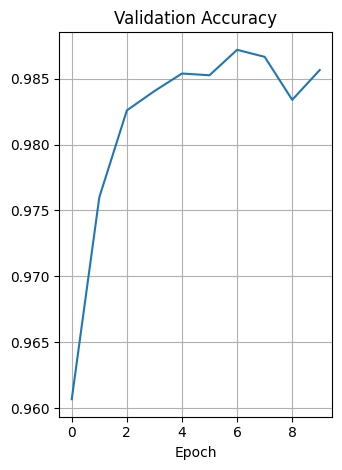

In [ ]:
plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

---
After you obtain your highest accuracy on the Test Set

Summarize:
- Your final/Best CNN architecture (list all layers)
- Final validation and test accuracy
- Anything you experimented with (kernel sizes, number of kernels, dropout, etc.)
- Plot the effect of number of epochs on accuracy for your best CNN


My final best CNN architecture was CNN #2 and its final validation and test accuracy were: 98.71%.

I experimented with pretty the numbers a lot, such as kernel sizes, padding, stride, dropout, and even removed the max-pooling function for one of the CNNs like the sample artitecture does.